17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(25000, 200) (25000, 200)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710,209 (2.71 MB)

 Trainable params: 710,209 (2.71 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 132s 814ms/step - accuracy: 0.7121 - loss: 0.5413 - val_accuracy: 0.8606 - val_loss: 0.3338
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 123s 783ms/step - accuracy: 0.8887 - loss: 0.2829 - val_accuracy: 0.8436 - val_loss: 0.3563
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 137s 753ms/step - accuracy: 0.9226 - loss: 0.2108 - val_accuracy: 0.8700 - val_loss: 0.3299
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 163s 1s/step - accuracy: 0.9510 - loss: 0.1428 - val_accuracy: 0.8632 - val_loss: 0.3578
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 138s 876ms/step - accuracy: 0.9694 - loss: 0.0966 - val_accuracy: 0.8586 - val_loss: 0.4296
196/196 ━━━━━━━━━━━━━━━━━━━━ 44s 224ms/step - accuracy: 0.8449 - loss: 0.3888
Test loss: 0.3888 | Test accuracy: 0.8449


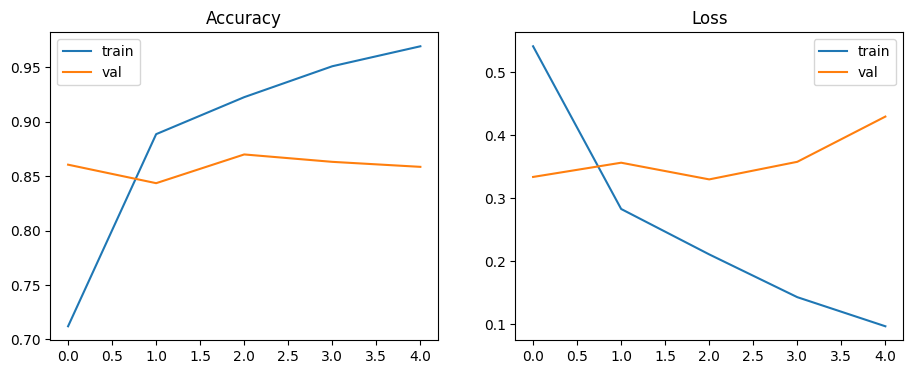

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
this movie was absolutely fantastic and I loved it -> POSITIVE (0.919)
terrible plot and awful acting a complete waste of time -> NEGATIVE (0.000)


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Settings
VOCAB_SIZE = 10000   # keep top 10k words
MAX_LEN = 200        # truncate/pad reviews to 200 tokens
EMBED_DIM = 64
BATCH_SIZE = 128
EPOCHS = 5

# Data
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
x_train = pad_sequences(x_train, maxlen=MAX_LEN, padding="post", truncating="post")
x_test  = pad_sequences(x_test,  maxlen=MAX_LEN, padding="post", truncating="post")
print(x_train.shape, x_test.shape)

# Model: Embedding -> Bidirectional LSTM -> Dense
model = models.Sequential([
    layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.5),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])

# For a simple RNN or GRU instead, swap the LSTM layer:
#   layers.Bidirectional(layers.SimpleRNN(64))
#   layers.Bidirectional(layers.GRU(64))

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.build(input_shape=(None, MAX_LEN))
model.summary()

# Train
early_stop = callbacks.EarlyStopping(monitor="val_accuracy", patience=2,
                                     restore_best_weights=True)

history = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
)

# Evaluate
loss, acc = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE)
print(f"Test loss: {loss:.4f} | Test accuracy: {acc:.4f}")

# Plot training curves
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

# Predict on custom text
word_index = imdb.get_word_index()

def encode(text):
    tokens = [word_index.get(w, 2) + 3 for w in text.lower().split()]
    tokens = [t if t < VOCAB_SIZE else 2 for t in tokens]   # 2 = unknown
    return pad_sequences([tokens], maxlen=MAX_LEN, padding="post", truncating="post")

for text in ["this movie was absolutely fantastic and I loved it",
             "terrible plot and awful acting a complete waste of time"]:
    prob = model.predict(encode(text), verbose=0)[0][0]
    print(f"{text} -> {'POSITIVE' if prob > 0.5 else 'NEGATIVE'} ({prob:.3f})")

# Save
model.save("lstm_imdb.keras")